In [5]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel("lab_ticket_resolution.xlsx")

print(df.head())
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())
print(df.describe())

  ticket_id  complexity_score  lines_changed  team_experience_years  reopened  \
0     T0001                 6             67                    5.6         1   
1     T0002                 9             72                   11.5         0   
2     T0003                 6             49                    3.3         0   
3     T0004                 5             50                    9.6         1   
4     T0005                 3             33                    6.4         1   

   resolution_hours  
0             24.77  
1             33.43  
2             17.82  
3             19.54  
4             11.04  
(240, 6)
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
ticket_id                0
complexity_score         0
lines_changed            0
team_experience_years    0
reopened                 0
resolution_hours         

In [2]:
X = df[['complexity_score', 'team_experience_years']]
y = df['resolution_hours']

print("Features:", X.columns.tolist())
print("Target:", y.name)
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Features: ['complexity_score', 'team_experience_years']
Target: resolution_hours
Shape of X: (240, 2)
Shape of y: (240,)


In [3]:
# 3. Train and test split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (192, 2)
Testing features: (48, 2)
Training targets: (192,)
Testing targets: (48,)


In [4]:
# 4. Dummy Regressor

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

dummy = DummyRegressor(strategy='mean')

dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_test)

dummy_mae = mean_absolute_error(y_test, dummy_pred)
dummy_rmse = np.sqrt(mean_squared_error(y_test, dummy_pred))
dummy_r2 = r2_score(y_test, dummy_pred)

print("MAE:", round(dummy_mae, 2))
print("RMSE:", round(dummy_rmse, 2))
print("R2:", round(dummy_r2, 2))

MAE: 9.11
RMSE: 10.6
R2: -0.02


In [5]:
# 5. Linear Regression

from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
linear_r2 = r2_score(y_test, linear_pred)

print("MAE:", round(linear_mae, 2))
print("RMSE:", round(linear_rmse, 2))
print("R2:", round(linear_r2, 2))

MAE: 2.91
RMSE: 3.57
R2: 0.88


In [6]:
# 5. Polynomial Regression

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=42)

poly_results = {}

for degree in [2, 3]:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring='neg_mean_absolute_error'
    )

    poly_results[degree] = -scores.mean()

    print(f"Degree {degree} CV MAE: {-scores.mean():.2f}")

Degree 2 CV MAE: 3.13
Degree 3 CV MAE: 3.16


In [7]:
# Evaluate Polynomial Regression (Degree 2)

poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    LinearRegression()
)

poly_model.fit(X_train, y_train)

poly_pred = poly_model.predict(X_test)

poly_mae = mean_absolute_error(y_test, poly_pred)
poly_rmse = np.sqrt(mean_squared_error(y_test, poly_pred))
poly_r2 = r2_score(y_test, poly_pred)

print("MAE:", round(poly_mae, 2))
print("RMSE:", round(poly_rmse, 2))
print("R2:", round(poly_r2, 2))

MAE: 3.02
RMSE: 3.74
R2: 0.87


In [8]:
# 7. Ridge and Lasso Regression

from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

alphas = [0.01, 0.1, 1, 10, 100]

ridge_search = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    {'ridge__alpha': alphas},
    cv=cv,
    scoring='neg_mean_absolute_error'
)

lasso_search = GridSearchCV(
    make_pipeline(StandardScaler(), Lasso(max_iter=10000)),
    {'lasso__alpha': alphas},
    cv=cv,
    scoring='neg_mean_absolute_error'
)

ridge_search.fit(X_train, y_train)
lasso_search.fit(X_train, y_train)

ridge_model = ridge_search.best_estimator_
lasso_model = lasso_search.best_estimator_

print("Best Ridge alpha:", ridge_search.best_params_['ridge__alpha'])
print("Best Lasso alpha:", lasso_search.best_params_['lasso__alpha'])

Best Ridge alpha: 0.01
Best Lasso alpha: 0.01


In [9]:
# 7b. Evaluate Ridge and Lasso

ridge_pred = ridge_model.predict(X_test)
lasso_pred = lasso_model.predict(X_test)

print("Ridge Regression")
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))
ridge_r2 = r2_score(y_test, ridge_pred)

print("MAE:", round(ridge_mae, 2))
print("RMSE:", round(ridge_rmse, 2))
print("R2:", round(ridge_r2, 2))

print("\nLasso Regression")
lasso_mae = mean_absolute_error(y_test, lasso_pred)
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_pred))
lasso_r2 = r2_score(y_test, lasso_pred)

print("MAE:", round(lasso_mae, 2))
print("RMSE:", round(lasso_rmse, 2))
print("R2:", round(lasso_r2, 2))

Ridge Regression
MAE: 2.91
RMSE: 3.57
R2: 0.88

Lasso Regression
MAE: 2.91
RMSE: 3.57
R2: 0.88


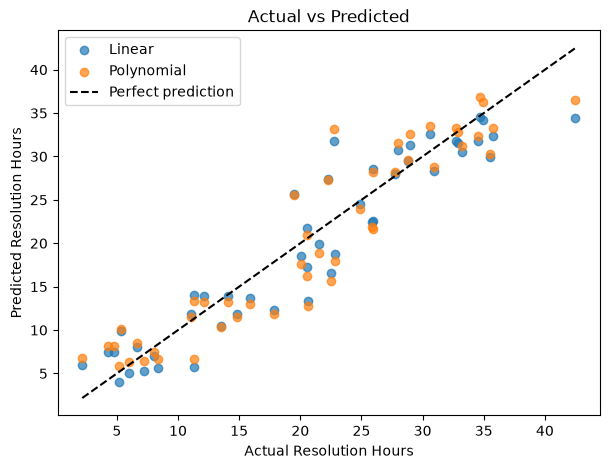

In [10]:
# 8. Observed vs Predicted

plt.figure(figsize=(7, 5))

plt.scatter(y_test, linear_pred, label="Linear", alpha=0.7)
plt.scatter(y_test, poly_pred, label="Polynomial", alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'k--',
    label="Perfect prediction"
)

plt.xlabel("Actual Resolution Hours")
plt.ylabel("Predicted Resolution Hours")
plt.title("Actual vs Predicted")
plt.legend()
plt.show()

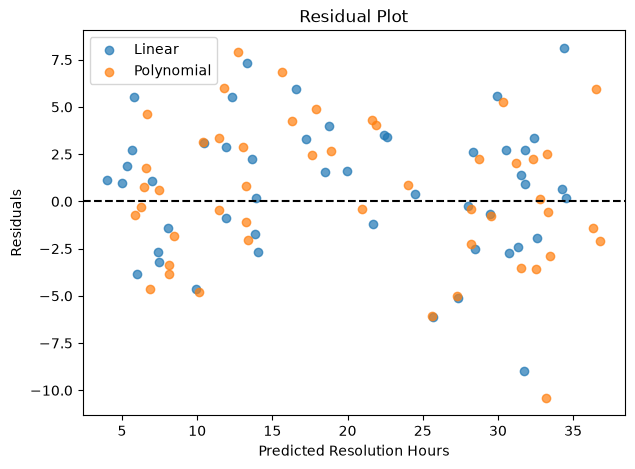

In [11]:
# Residual Plot

linear_residuals = y_test - linear_pred
poly_residuals = y_test - poly_pred

plt.figure(figsize=(7, 5))

plt.scatter(linear_pred, linear_residuals,
            label="Linear", alpha=0.7)

plt.scatter(poly_pred, poly_residuals,
            label="Polynomial", alpha=0.7)

plt.axhline(0, color="black", linestyle="--")

plt.xlabel("Predicted Resolution Hours")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.legend()

plt.show()

In [15]:
# Recommendation

# Linear Regression because it had a low MAE of 2.91 hours, RMSE of 3.57, and R² of 0.88. Ridge and Lasso had similar results, while Polynomial Regression performed slightly worse.

In [16]:
# Compare degree 1, 2 and 3

from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

for degree in [1, 2, 3]:
    model = make_pipeline(
        PolynomialFeatures(degree),
        LinearRegression()
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print("Degree:", degree)
    print("Actual:", y_test.values[:5])
    print("Predicted:", y_pred[:5].round(2))
    print()

Degree: 1
Actual: [20.62 22.8   7.19  5.97 25.98]
Predicted: [13.3  18.79  5.33  5.01 22.6 ]

Degree: 2
Actual: [20.62 22.8   7.19  5.97 25.98]
Predicted: [12.73 17.93  6.44  6.28 21.65]

Degree: 3
Actual: [20.62 22.8   7.19  5.97 25.98]
Predicted: [13.87 17.37  7.04  7.34 22.78]



In [17]:
# Actual vs Predicted values

model = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred.round(2)
})

print(results.head(10))

   Actual  Predicted
0   20.62      12.73
1   22.80      17.93
2    7.19       6.44
3    5.97       6.28
4   25.98      21.65
5    4.74       8.11
6   12.12      13.22
7   28.02      31.55
8   28.80      29.56
9   35.55      30.31


In [18]:
# selected Polynomial Regression and tested degrees 1, 2, and 3. I trained the models using X_train and y_train, then predicted values using X_test. Finally, I compared y_test, which contains the actual values, with y_pred, which contains the predicted values.

In [1]:
# Q10 - Mean Baseline
# It gives a basic result to compare with other models.
# It predicts the average resolution time.


In [2]:
# Q11
# Linear, Ridge and Lasso all had MAE = 2.91 and RMSE = 3.57.
# Their rounded results are the same.
# MAE measures average error, while RMSE penalizes large errors more.

In [3]:
# Q12
# Degree 2 CV MAE = 3.13
# Degree 3 CV MAE = 3.16
# Degree 2 performed slightly better.
# Degree 3 is more complex but did not improve validation results.
# This could indicate some overfitting.


In [4]:
# Q13
# Ridge and Lasso selected alpha = 0.01.
# Their performance was almost the same as Linear Regression.
# Regularization reduces coefficient sizes.
# The effect on coefficients was not directly measured here.

In [5]:
# Q14 
# Scaling puts features on comparable scales.
# This helps Ridge and Lasso apply regularization fairly.

In [6]:
# Q15
# Lines changed and reopened may only be known after work begins.
# I excluded them to prevent data leakage.

In [7]:
# Q16
# A random split may not be suitable for time-based data.
# For tickets collected over years, a chronological split is better.
# Related tickets from the same customer or team should stay grouped.

In [8]:
# Q17 
# Test the model using real and newer ticket data.
# Check prediction errors and data leakage.
# Monitor performance and retrain when needed.